First attach the Bank-Full Excel CsV file!

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv('bank-full.csv', sep=';')
df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no


In [2]:
df.isna().sum() # checking for missing values in the dataset

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [3]:
df = df.dropna() # then removing any missing values

In [4]:
df.isna().sum() # check again that all the values are 0 and its cleaned.

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


In [5]:
df['job'].unique() # looking at the one column

array(['management', 'technician', 'entrepreneur', 'blue-collar',
       'unknown', 'retired', 'admin.', 'services', 'self-employed',
       'unemployed', 'housemaid', 'student'], dtype=object)

In [6]:
categorical_cols = [ # required columns so that values are numeric
    'job',
    'marital',
    'education',
    'default',
    'housing',
    'loan',
    'contact',
    'month',
    'poutcome',
    'y'
]

for col in categorical_cols:
    df[col] = pd.factorize(df[col])[0]

In [32]:
df.info() #just to check...

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 45211 entries, 0 to 45210
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   age        45211 non-null  int64
 1   job        45211 non-null  int64
 2   marital    45211 non-null  int64
 3   education  45211 non-null  int64
 4   default    45211 non-null  int64
 5   balance    45211 non-null  int64
 6   housing    45211 non-null  int64
 7   loan       45211 non-null  int64
 8   contact    45211 non-null  int64
 9   day        45211 non-null  int64
 10  month      45211 non-null  int64
 11  duration   45211 non-null  int64
 12  campaign   45211 non-null  int64
 13  pdays      45211 non-null  int64
 14  previous   45211 non-null  int64
 15  poutcome   45211 non-null  int64
 16  y          45211 non-null  int64
dtypes: int64(17)
memory usage: 5.9 MB


In [8]:
df.head() # making sure the values are numerical now

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,0,0,0,0,2143,0,0,0,5,0,261,1,-1,0,0,0
1,44,1,1,1,0,29,0,0,0,5,0,151,1,-1,0,0,0
2,33,2,0,1,0,2,0,1,0,5,0,76,1,-1,0,0,0
3,47,3,0,2,0,1506,0,0,0,5,0,92,1,-1,0,0,0
4,33,4,1,2,0,1,1,0,0,5,0,198,1,-1,0,0,0


In [9]:
X = df.drop('y', axis=1) # created the X and Y

y = df['y']

In [10]:
from sklearn.model_selection import train_test_split  # make sure every libraries are laoded.

In [11]:
X_train, X_test, y_train, y_test = train_test_split( ##traininig part and stratified is done
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=42
)

In [12]:
print(X_train.shape) # just a check
print(X_test.shape)

(31647, 16)
(13564, 16)


In [13]:
from sklearn.naive_bayes import GaussianNB # Building the Naive bayed model

model = GaussianNB()
model.fit(X_train, y_train)

GaussianNB()

In [14]:
y_pred = model.predict(X_test) #predictions

In [15]:
from sklearn.metrics import (   ## calculating the Accuracy and F1
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    classification_report
)

accuracy = accuracy_score(y_pred, y_test)

f1 = f1_score(y_pred, y_test, average="weighted")

print("The accuracy of my Naive Bayes Model is:", accuracy)
print("The F1 Score of my Naive Bayes Model is:", f1)

#accuracy is 84.92%
#F1 score = 84.04%

The accuracy of my Naive Bayes Model is: 0.8492332645237393
The F1 Score of my Naive Bayes Model is: 0.8403943552195242


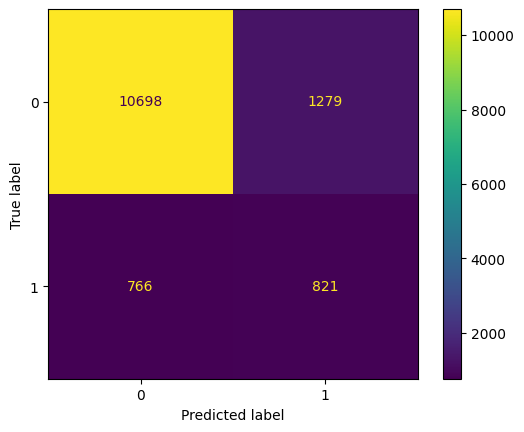

In [16]:
import matplotlib.pyplot as plt  ## check for confusion matrix as spoken in the office hours
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred
)
plt.show()

I ran these interations and changed the random states and recorded the data

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=1
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8425243291064582
F1: 0.8532992279191679


In [18]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=2
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8427455028015335
F1: 0.8528710814565095


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=3
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8459893836626364
F1: 0.8554239985687002


In [20]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=4
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8439988204069596
F1: 0.8545069426002209


In [21]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=5
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8486434680035387
F1: 0.858444297270753


In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=6
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8414184606310823
F1: 0.85197301315367


In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=7
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8482011206133884
F1: 0.8570716955962285


In [24]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=8
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8501179593040401
F1: 0.8595218031253489


In [25]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=9
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8426717782365084
F1: 0.8533252072082028


In [26]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.30,
    stratify=y,
    random_state=10
)

model = GaussianNB()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.843335299321734
F1: 0.8540961458334875


In [27]:
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, f1_score

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    train_size=0.90,   # 10% training
    test_size=0.10,    # 90% testing
    stratify=y,
    random_state=1
)

model = GaussianNB()

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

f1 = f1_score(y_test, y_pred, average="weighted")

print("Accuracy:", accuracy)
print("F1:", f1)

Accuracy: 0.8343653250773994
F1: 0.8455374550474534


In [28]:
accuracy_scores = []
f1_scores = []

for i in range(1, 11):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        train_size=0.10,
        test_size=0.90,
        stratify=y,
        random_state=i
    )

    model = GaussianNB()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy_scores.append(
        accuracy_score(y_test, y_pred)
    )

    f1_scores.append(
        f1_score(y_test, y_pred, average="weighted")
    )

print("Mean Accuracy:", np.mean(accuracy_scores))
print("Std Accuracy:", np.std(accuracy_scores))

print("Mean F1:", np.mean(f1_scores))
print("Std F1:", np.std(f1_scores))

Mean Accuracy: 0.8473187515360039
Std Accuracy: 0.006089700442697029
Mean F1: 0.8563238523690723
Std F1: 0.00393528298985269


I created this, for loop so it runs 10 times and I only changed the train_size and test_size, for instance, I started with 90% and 10% and kept changing the numbers until 90/10 and recorded the data.

In [29]:
accuracy_scores = []
f1_scores = []

for i in range(1, 11):

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        train_size=0.90,
        test_size=0.10,
        stratify=y,
        random_state=i
    )

    model = GaussianNB()
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    accuracy_scores.append(
        accuracy_score(y_test, y_pred)
    )

    f1_scores.append(
        f1_score(y_test, y_pred, average="weighted")
    )

print("Mean Accuracy:", np.mean(accuracy_scores))
print("Std Accuracy:", np.std(accuracy_scores))

print("Mean F1:", np.mean(f1_scores))
print("Std F1:", np.std(f1_scores))

Mean Accuracy: 0.845842547545334
Std Accuracy: 0.0054487387031109755
Mean F1: 0.8555120316764764
Std F1: 0.004605786867535061


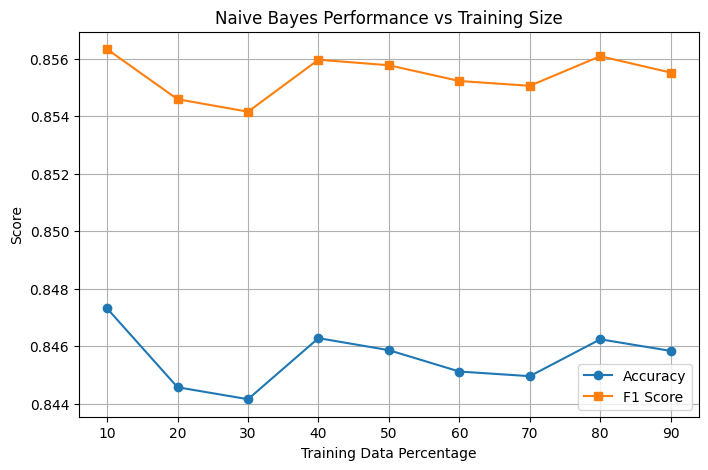

In [30]:
# visual plot using accuracy and f1 results
import matplotlib.pyplot as plt

train_sizes = [10, 20, 30, 40, 50, 60, 70, 80, 90]

accuracy_means = [
    0.847319,
    0.844580,
    0.844164,
    0.846286,
    0.845868,
    0.845126,
    0.844965,
    0.846246,
    0.845843
]

f1_means = [
    0.856324,

    0.854587,
    0.854153,
    0.855959,
    0.855767,
    0.855220,
    0.855053,
    0.856081,
    0.855512
]

plt.figure(figsize=(8,5))

plt.plot(train_sizes, accuracy_means, marker='o', label='Accuracy')
plt.plot(train_sizes, f1_means, marker='s', label='F1 Score')

plt.xlabel('Training Data Percentage')
plt.ylabel('Score')
plt.title('Naive Bayes Performance vs Training Size')
plt.legend()
plt.grid(True)

plt.show()